# SSL-DACL: Dual Agreement Consistency Learning (DACL) for semi-supervised blood cell segmentation

The method studied in this project (Wang et al., 2026).

**DACL** trains a lightweight CNN (UNeXt, $f^1$) together with a Transformer (Swin-Unet, $f^2$) and an EMA teacher of the Transformer ($f^{ema}$). **Only UNeXt is used for inference.**

$$\mathcal{L}_{total} = (\mathcal{L}^1_{sup} + \mathcal{L}^2_{sup}) + \lambda(\mathcal{L}^1_{cps} + \mathcal{L}^2_{cps}) + \tau\,\mathcal{L}_{ict} + \beta\,\mathcal{L}_{dac}$$

- $\mathcal{L}_{sup}$: Cross-Entropy + Dice on labeled images.
- $\mathcal{L}_{cps}$: Cross-Entropy + Dice against the one-hot prediction of the other network, on unlabeled images (Eq. 1).
- $\mathcal{L}_{ict}$: MSE between $f^2(\mathrm{Mix}(u_i, u_j))$ and $\mathrm{Mix}(f^{ema}(u_i), f^{ema}(u_j))$, with mixing ratio $\sigma = 0.5$.
- $\mathcal{L}_{dac} = \mathcal{L}_{KL} + \mathcal{L}_{ent}$: pixel-wise $\mathrm{KL}(p\|q)$ plus $H(p) + H(q) - H\big(\tfrac{p+q}{2}\big)$, where $p, q$ are the predictions of UNeXt and Swin-Unet.

Notebook outline:
1. Experiment configuration
2. Data preparation & splitting (**same split as the FS notebooks**)
3. Data augmentation
4. Dataset / DataLoader (labeled + unlabeled streams)
5. Models (UNeXt + Swin-Unet)
6. Loss & evaluation metrics
7. Training loop
8. Experiments at 5% and 10% labels
9. Results

## 1. Experiment configuration

In [1]:
# ================================================================
#                    EXPERIMENT CONFIGURATION
#  Edit this cell only. All cells below read their settings from CFG.
# ================================================================
class CFG:
    # ---------------- PATHS ----------------
    # Kaggle dataset folder containing Original/ (images) and Mask/ (masks).
    # If this path does not exist, the folder is searched automatically under /kaggle/input.
    RAW_DIR = "/kaggle/input/bloodcell/bloodcell_dataset"
    IMAGE_SUBDIR = "Original"
    MASK_SUBDIR = "Mask"
    # Where prepared data and results are written. On Kaggle only /kaggle/working is kept.
    WORK_DIR = "/kaggle/working"

    # ---------------- METHOD & MODEL ----------------
    MODEL = "dacl"          # used to name the run folders: runs/dacl_<ratio>p_s<seed>
    # UNeXt channel configuration - keep the SAME value as in FS_UNeXt and DACL.
    #   "dacl" (32, 64, 128, 160, 256) -> 1.58M params | "original" (16, 32, ...) -> 1.47M params
    UNEXT_VARIANT = "dacl"
    NUM_CLASSES = 2          # 0 = background, 1 = cell

    # ---------------- DATA ----------------
    PREP_SIZE = (640, 480)   # images are resized once to this size (width, height)
    MASK_THRESHOLD = 127     # mask pixels > threshold are cell
    IMG_SIZE = 224           # network input size (same for every method)
    # KEEP the same split ratios and seed as all other notebooks -> identical labeled/unlabeled/test sets.
    SPLIT_RATIOS = (0.7, 0.1, 0.2)
    SPLIT_SEED = 2026
    # Label ratios (%) to run. The rest of the training set is used WITHOUT labels.
    LABELED_RATIOS = [5, 10]

    # ---------------- TRAINING ----------------
    MAX_ITERS = 30000        # iteration-based training (same as the FS notebooks)
    # Batch composition as in the DACL paper: 1 labeled + 4 unlabeled images per iteration.
    # Both are concatenated into one forward pass (shared BatchNorm statistics).
    LABELED_BS = 1
    UNLABELED_BS = 4
    # Augmentation level for UNLABELED images. The DACL paper augments labeled data only -> "none".
    UNLABELED_AUG = "none"   # "none" | "basic" | "full"
    # SGD as in the DACL paper, poly learning-rate decay lr*(1 - it/max_it)^0.9.
    BASE_LR = 0.01
    MOMENTUM = 0.9
    WEIGHT_DECAY = 1e-4
    USE_AMP = True           # FP16 mixed precision on GPU
    NUM_WORKERS = 4
    SEEDS = [2026]           # add 2027, 2028 for mean ± std over runs

    # ---------------- SWIN-UNET (second network) ----------------
    # Initial weights:
    #   "imagenet"   -> download Microsoft's Swin-T (ImageNet-1K) - Internet must be ON
    #   "/kaggle/input/.../swin_tiny_patch4_window7_224.pth" -> uploaded file (Internet OFF)
    #   ""           -> random init (not recommended; DACL uses the pretrained model)
    PRETRAINED = "imagenet"
    # Stochastic depth of the Transformer blocks. Same value as FS Swin-Unet.
    DROP_PATH = 0.1

    # ---------------- DACL ----------------
    # Trade-off weights of the total loss, from the DACL paper.
    LAMBDA_CPS = 0.2         # cross pseudo supervision
    TAU_ICT = 0.2            # interpolation consistency with the EMA teacher
    BETA_DAC = 1.0          # dual-agreement consistency (KL + entropy)
    # Entropy term of L_dac. False keeps only the KL term (to measure the effect of the entropy term).
    USE_L_ENT = True
    # Mixup ratio of L_ict (fixed in DACL).
    MIX_SIGMA = 0.5
    # EMA decay of the teacher, which follows Swin-Unet. The paper gives no value; 0.99 as in the other notebooks.
    EMA_DECAY = 0.99
    # The three unsupervised weights grow from 0 with a sigmoid ramp-up over this many iterations
    # (same value as the baselines). The paper does not mention a ramp-up, but with 0 (full weights from
    # the first iteration) both networks collapsed to predicting a single class in a dry run.
    RAMPUP_ITERS = 12000

    # ---------------- EVALUATION & LOGGING ----------------
    VAL_INTERVAL = 500       # validate every N iterations; keep best.pth (highest validation Dice)
    LOG_INTERVAL = 100

    # ---------------- DRY RUN ----------------
    # True -> 300 iterations per experiment to test the notebook quickly. Set False for the real run.
    DEBUG = False


if CFG.DEBUG:
    CFG.MAX_ITERS, CFG.VAL_INTERVAL, CFG.LOG_INTERVAL = 300, 100, 50
    CFG.RAMPUP_ITERS = 100

In [2]:
import csv, json, os, random, re, shutil, time
from pathlib import Path

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, Dataset
import albumentations as A
from albumentations.pytorch import ToTensorV2
from scipy import ndimage
from skimage.color import hed2rgb, rgb2hed
from timm.layers import DropPath, to_2tuple, trunc_normal_
from tqdm.auto import tqdm

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
DATA_DIR = Path(CFG.WORK_DIR) / "data" / "processed"
SPLIT_DIR = Path(CFG.WORK_DIR) / "data" / "splits"
RUN_ROOT = Path(CFG.WORK_DIR) / "runs"
print("torch", torch.__version__, "| albumentations", A.__version__, "| device:", DEVICE)
if DEVICE.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

torch 2.11.0+cu130 | albumentations 2.0.8 | device: cuda
GPU: Tesla T4


## 2. Data preparation & splitting

- Pair `Original/<name>` with `Mask/<name>` by file name (extension and suffixes such as `_mask` are ignored), resize, binarize masks.
- **70/10/20** split (train/val/test) with a fixed seed; the first **2/5/10/20%** of train are the labeled subsets.
- This cell **skips itself** if the data was already prepared in the current session.

> Check the log: **1328 pairs** must be found, and the cell-pixel ratio must not be close to 0 or 1.

In [3]:
EXTS = {".png", ".jpg", ".jpeg", ".bmp", ".tif", ".tiff"}
# Suffixes ignored when matching names, e.g. "12_mask.png" in Mask/ pairs with "12.jpg" in Original/.
SUFFIX_RE = re.compile(r"[ _\-]?(mask|masks|gt|label|labels|image|images|img|original)$", re.I)


def find_raw_dir():
    """Return the folder containing IMAGE_SUBDIR and MASK_SUBDIR."""
    root = Path(CFG.RAW_DIR)
    if (root / CFG.IMAGE_SUBDIR).is_dir() and (root / CFG.MASK_SUBDIR).is_dir():
        return root
    for cand in Path("/kaggle/input").rglob(CFG.MASK_SUBDIR):
        if cand.is_dir() and (cand.parent / CFG.IMAGE_SUBDIR).is_dir():
            print(f"CFG.RAW_DIR not found - using {cand.parent}")
            return cand.parent
    raise FileNotFoundError(f"No folder with {CFG.IMAGE_SUBDIR}/ and {CFG.MASK_SUBDIR}/ found - check CFG.RAW_DIR.")


def _index(folder):
    files = sorted(p for p in folder.rglob("*") if p.suffix.lower() in EXTS)
    return {SUFFIX_RE.sub("", p.stem).strip().lower(): p for p in files}


def prepare_dataset():
    if (DATA_DIR / "DONE").exists():
        print("Data already prepared - skipping.")
        return
    raw = find_raw_dir()
    images, masks = _index(raw / CFG.IMAGE_SUBDIR), _index(raw / CFG.MASK_SUBDIR)
    keys = sorted(set(images) & set(masks))
    print(f"Found {len(images)} images, {len(masks)} masks -> {len(keys)} pairs")
    if len(keys) < max(len(images), len(masks)):
        print("  unmatched images (examples):", [images[k].name for k in sorted(set(images) - set(masks))[:5]])
        print("  unmatched masks  (examples):", [masks[k].name for k in sorted(set(masks) - set(images))[:5]])
    if not keys:
        raise RuntimeError("No image/mask pairs found - the file names in the two folders do not match.")
    for k in keys[:3]:
        print(f"  pair: {images[k].name}  <->  {masks[k].name}")
    (DATA_DIR / "images").mkdir(parents=True, exist_ok=True)
    (DATA_DIR / "masks").mkdir(parents=True, exist_ok=True)
    fg = []
    for i, k in enumerate(tqdm(keys, desc="Preparing")):
        img = cv2.imread(str(images[k]), cv2.IMREAD_COLOR)
        msk = cv2.imread(str(masks[k]), cv2.IMREAD_GRAYSCALE)
        if img is None or msk is None:
            print("  skipping unreadable file:", k)
            continue
        img = cv2.resize(img, CFG.PREP_SIZE, interpolation=cv2.INTER_AREA)
        msk = cv2.resize(msk, CFG.PREP_SIZE, interpolation=cv2.INTER_NEAREST)
        msk = np.where(msk > CFG.MASK_THRESHOLD, 255, 0).astype(np.uint8)
        cv2.imwrite(str(DATA_DIR / "images" / f"{i:04d}.png"), img)
        cv2.imwrite(str(DATA_DIR / "masks" / f"{i:04d}.png"), msk)
        fg.append((msk > 0).mean())
    (DATA_DIR / "DONE").write_text("ok")
    print(f"Saved {len(fg)} pairs | mean cell-pixel ratio: {np.mean(fg):.3f}")


def split_dataset():
    names = sorted(p.stem for p in (DATA_DIR / "images").glob("*.png"))
    random.Random(CFG.SPLIT_SEED).shuffle(names)
    n = len(names)
    n_tr, n_va = round(CFG.SPLIT_RATIOS[0] * n), round(CFG.SPLIT_RATIOS[1] * n)
    split = {"train": names[:n_tr], "val": names[n_tr:n_tr + n_va], "test": names[n_tr + n_va:]}
    for pct in (2, 5, 10, 20):  # 2% for the extreme low-label experiment
        split[f"labeled_{pct}"] = split["train"][:int(len(split["train"]) * pct / 100)]
    SPLIT_DIR.mkdir(parents=True, exist_ok=True)
    for k, v in split.items():
        (SPLIT_DIR / f"{k}.txt").write_text("\n".join(v) + "\n", encoding="utf-8")
    print({k: len(v) for k, v in split.items()})
    return split


prepare_dataset()
SPLIT = split_dataset()

CFG.RAW_DIR not found - using /kaggle/input/datasets/vuduybinh1/bloodcell/bloodcell_dataset
Found 1328 images, 1328 masks -> 1328 pairs
  pair: 002f20ad-2ace-499c-9335-c9080bc3e6b5.png  <->  002f20ad-2ace-499c-9335-c9080bc3e6b5.png
  pair: 003a89b0-a095-417a-8dd6-f408339bbc68.png  <->  003a89b0-a095-417a-8dd6-f408339bbc68.png
  pair: 003d1cdc-0aec-430b-90e0-f4d82135b1ac.png  <->  003d1cdc-0aec-430b-90e0-f4d82135b1ac.png


Preparing:   0%|          | 0/1328 [00:00<?, ?it/s]

Saved 1328 pairs | mean cell-pixel ratio: 0.294
{'train': 930, 'val': 133, 'test': 265, 'labeled_2': 18, 'labeled_5': 46, 'labeled_10': 93, 'labeled_20': 186}


## 3. Data augmentation

Applied to **labeled training images only**; validation/test are only resized + normalized.
Augmentation is **online**: every time an image is loaded a new random variant is generated, so over
30k iterations the model practically never sees the same image twice – no need to write extra
augmented images to disk (offline augmentation).

| Group | Transform | What it simulates |
|---|---|---|
| Geometric | Horizontal/vertical flip, 90° rotation | Cells have no canonical orientation |
| | Affine (scale, small rotation, translation) | Different magnification and slide placement |
| | Elastic | Slight cell-shape deformation |
| Color / stain | Color jitter | Different lamps, cameras, white balance |
| | **HED stain jitter** | Stronger/weaker staining between slides and labs |
| | Gamma, CLAHE | Different contrast and exposure |
| Image quality | Gaussian blur, Gaussian noise | Imperfect focus, sensor noise |

**`LEVEL`** – use it for an augmentation ablation:
- `"none"`: no augmentation · `"basic"`: geometric only · `"full"`: geometric + color/stain + image quality

In this notebook `AUG` applies to **labeled** images; unlabeled images follow `CFG.UNLABELED_AUG`.

In [4]:
# ================================================================
#                DATA AUGMENTATION CONFIGURATION
#  p = probability of applying each transform to an image (0 = off, 1 = always)
# ================================================================
class AUG:
    LEVEL = "full"            # "none" | "basic" | "full"

    # ---- Geometric (applied to the image AND the mask) ----
    HFLIP_P = 0.5             # horizontal flip
    VFLIP_P = 0.5             # vertical flip
    ROT90_P = 0.5             # rotate by 90/180/270 degrees
    AFFINE_P = 0.5            # affine transform:
    SCALE = (0.85, 1.15)      #   scale 0.85-1.15x (magnification differences)
    ROTATE = (-15, 15)        #   extra rotation ±15 degrees
    TRANSLATE = (-0.05, 0.05) #   shift ±5% of the image size
    ELASTIC_P = 0.2           # elastic deformation
    ELASTIC_ALPHA = 30        #   strength (too large distorts cell shapes unrealistically)
    ELASTIC_SIGMA = 6         #   smoothness of the displacement field

    # ---- Color / stain (image ONLY, the mask is unchanged) ----
    COLOR_JITTER_P = 0.5
    BRIGHTNESS = 0.2          # brightness ±20%
    CONTRAST = 0.2            # contrast ±20%
    SATURATION = 0.2          # saturation ±20%
    HUE = 0.05                # hue ±0.05 (kept small so cell colors stay plausible)
    HED_P = 0.5               # stain jitter in HED color space (Hematoxylin-Eosin-DAB):
    HED_SIGMA = 0.05          #   per-channel multiplicative factor ~ U(1-σ, 1+σ)
    HED_BIAS = 0.005          #   per-channel additive shift ~ U(-b, b). skimage HED values lie in
                              #   ~[0, 0.1], so b must be SMALL; b = 0.02 already whitened the background.
                              #   (Blood smears use Giemsa/Wright stain; HED is a reasonable
                              #    approximation of the purple/pink dyes and standard in histopathology.)
    GAMMA_P = 0.2
    GAMMA = (80, 120)         # gamma 0.8-1.2 (in %)
    CLAHE_P = 0.1             # contrast-limited adaptive histogram equalization

    # ---- Image quality ----
    BLUR_P = 0.1              # Gaussian blur (defocus)
    NOISE_P = 0.1             # Gaussian noise (sensor noise)
    NOISE_STD = (0.01, 0.04)  #   noise std on a [0, 1] scale (0.04 ≈ ±10 grey levels)

    # ---- Normalization ----
    # ImageNet statistics: required by the pretrained Swin-Unet; shared with UNeXt so
    # both models receive identical inputs.
    MEAN = (0.485, 0.456, 0.406)
    STD = (0.229, 0.224, 0.225)

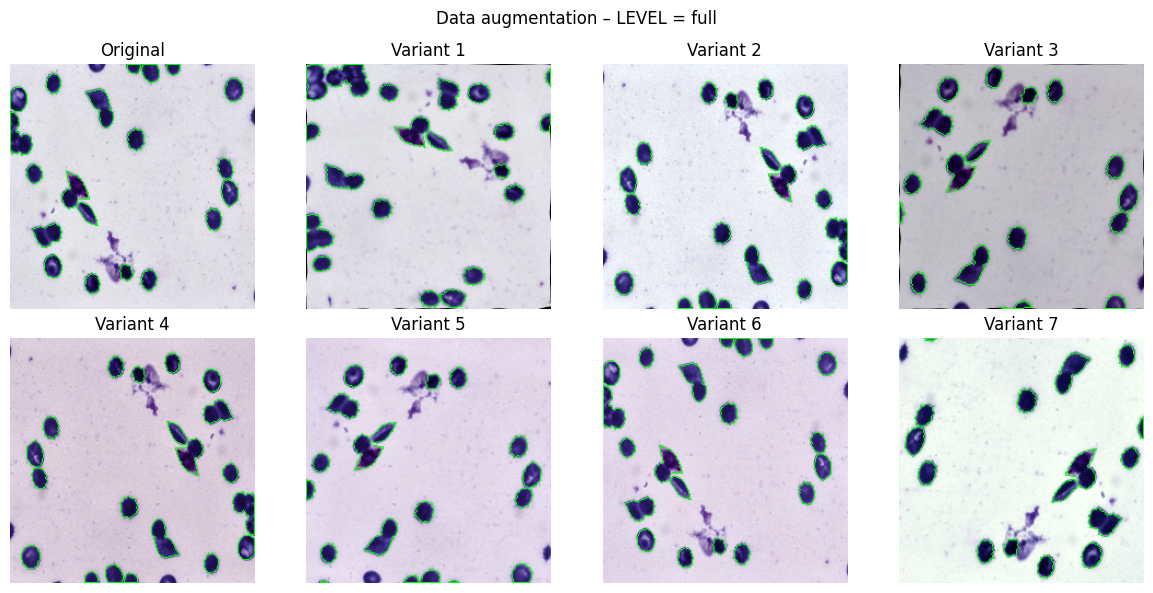

In [5]:
# albumentations 1.x and 2.x use different argument names -> two helpers support both.
ALB_V2 = int(A.__version__.split(".")[0]) >= 2


def _affine():
    # Empty areas created by rotation/scaling are filled by reflection (no artificial black borders).
    border = {"border_mode": cv2.BORDER_REFLECT_101} if ALB_V2 else {"mode": cv2.BORDER_REFLECT_101}
    return A.Affine(scale=AUG.SCALE, rotate=AUG.ROTATE, translate_percent=AUG.TRANSLATE,
                    p=AUG.AFFINE_P, **border)


def _noise():
    if ALB_V2:
        return A.GaussNoise(std_range=AUG.NOISE_STD, p=AUG.NOISE_P)
    var = tuple((s * 255) ** 2 for s in AUG.NOISE_STD)  # 1.x uses variance on a 0-255 scale
    return A.GaussNoise(var_limit=var, p=AUG.NOISE_P)


def hed_jitter(img, **kwargs):
    """HED stain jitter (Tellez et al., 2018): RGB -> HED, perturb each channel, back to RGB."""
    hed = rgb2hed(img.astype(np.float32) / 255.0)
    alpha = np.random.uniform(1 - AUG.HED_SIGMA, 1 + AUG.HED_SIGMA, 3)
    beta = np.random.uniform(-AUG.HED_BIAS, AUG.HED_BIAS, 3)
    rgb = hed2rgb(hed * alpha + beta)
    return (np.clip(rgb, 0, 1) * 255).astype(np.uint8)


def build_train_transform(level=None, normalize=True):
    level = level or AUG.LEVEL
    t = [A.Resize(CFG.IMG_SIZE, CFG.IMG_SIZE)]
    if level in ("basic", "full"):
        t += [
            A.HorizontalFlip(p=AUG.HFLIP_P),
            A.VerticalFlip(p=AUG.VFLIP_P),
            A.RandomRotate90(p=AUG.ROT90_P),
            _affine(),
            A.ElasticTransform(alpha=AUG.ELASTIC_ALPHA, sigma=AUG.ELASTIC_SIGMA, p=AUG.ELASTIC_P),
        ]
    if level == "full":
        t += [
            A.ColorJitter(brightness=AUG.BRIGHTNESS, contrast=AUG.CONTRAST,
                          saturation=AUG.SATURATION, hue=AUG.HUE, p=AUG.COLOR_JITTER_P),
            A.Lambda(image=hed_jitter, p=AUG.HED_P),
            A.RandomGamma(gamma_limit=AUG.GAMMA, p=AUG.GAMMA_P),
            A.CLAHE(p=AUG.CLAHE_P),
            A.GaussianBlur(blur_limit=(3, 5), p=AUG.BLUR_P),
            _noise(),
        ]
    if normalize:
        t += [A.Normalize(mean=AUG.MEAN, std=AUG.STD), ToTensorV2()]
    return A.Compose(t)


def build_eval_transform():
    return A.Compose([A.Resize(CFG.IMG_SIZE, CFG.IMG_SIZE),
                      A.Normalize(mean=AUG.MEAN, std=AUG.STD), ToTensorV2()])


def show_augmentations(name=None, n=7, level=None):
    """Show the original + n augmented variants; green contour = transformed mask."""
    name = name or SPLIT["train"][0]
    img = cv2.cvtColor(cv2.imread(str(DATA_DIR / "images" / f"{name}.png")), cv2.COLOR_BGR2RGB)
    msk = (cv2.imread(str(DATA_DIR / "masks" / f"{name}.png"), 0) > 127).astype(np.uint8)
    tf = build_train_transform(level, normalize=False)
    base = A.Compose([A.Resize(CFG.IMG_SIZE, CFG.IMG_SIZE)])(image=img, mask=msk)
    samples = [("Original", base["image"], base["mask"])]
    for i in range(n):
        o = tf(image=img, mask=msk)
        samples.append((f"Variant {i + 1}", o["image"], o["mask"]))
    fig, axes = plt.subplots(2, (n + 2) // 2, figsize=(3 * ((n + 2) // 2), 6))
    for ax, (title, im, m) in zip(axes.ravel(), samples):
        vis = im.copy()
        cnts, _ = cv2.findContours(m.astype(np.uint8), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)
        cv2.drawContours(vis, cnts, -1, (0, 255, 0), 1)
        ax.imshow(vis); ax.set_title(title); ax.axis("off")
    plt.suptitle(f"Data augmentation – LEVEL = {level or AUG.LEVEL}")
    plt.tight_layout(); plt.show()


show_augmentations()

## 4. Dataset / DataLoader

Two infinite streams per iteration:
- **labeled**: `labeled_<ratio>.txt` images with masks, full augmentation (`AUG.LEVEL`);
- **unlabeled**: the remaining training images – their masks exist on disk but are **never used**.

In [6]:
class BloodCellDataset(Dataset):
    def __init__(self, names, transform):
        self.names, self.transform = list(names), transform

    def __len__(self):
        return len(self.names)

    def __getitem__(self, i):
        name = self.names[i]
        img = cv2.cvtColor(cv2.imread(str(DATA_DIR / "images" / f"{name}.png")), cv2.COLOR_BGR2RGB)
        msk = (cv2.imread(str(DATA_DIR / "masks" / f"{name}.png"), 0) > 127).astype(np.uint8)
        o = self.transform(image=img, mask=msk)
        return {"image": o["image"], "mask": torch.as_tensor(o["mask"]).long(), "name": name}


def infinite_loader(loader):
    """Iterate a DataLoader forever (iteration-based training)."""
    while True:
        for b in loader:
            yield b


def build_loaders(ratio, seed):
    labeled = SPLIT[f"labeled_{ratio}"]
    if not labeled:
        raise ValueError(f"No labeled images at {ratio}% - check LABELED_RATIOS / the data.")
    unlabeled = sorted(set(SPLIT["train"]) - set(labeled))
    g = torch.Generator(); g.manual_seed(seed)
    common = dict(drop_last=True, num_workers=CFG.NUM_WORKERS, pin_memory=DEVICE.type == "cuda",
                  persistent_workers=CFG.NUM_WORKERS > 0, generator=g, shuffle=True)
    unl_tf = build_eval_transform() if CFG.UNLABELED_AUG == "none" else build_train_transform(CFG.UNLABELED_AUG)
    lab_loader = DataLoader(BloodCellDataset(labeled, build_train_transform()),
                            batch_size=min(CFG.LABELED_BS, len(labeled)), **common)
    unl_loader = DataLoader(BloodCellDataset(unlabeled, unl_tf), batch_size=CFG.UNLABELED_BS, **common)
    val_loader = DataLoader(BloodCellDataset(SPLIT["val"], build_eval_transform()), batch_size=8,
                            num_workers=CFG.NUM_WORKERS)
    print(f"   labeled: {len(labeled)} | unlabeled: {len(unlabeled)} | val: {len(SPLIT['val'])}")
    return infinite_loader(lab_loader), infinite_loader(unl_loader), val_loader

## 5. Models

UNeXt (Valanarasu & Patel, MICCAI 2022) is the deployed network. Swin-Unet (Cao et al., ECCV-W 2022) is the second network used only during training.

In [7]:
"""UNeXt: MLP-based Rapid Medical Image Segmentation Network (Valanarasu & Patel, MICCAI 2022).

Re-implemented from the official repo (jeya-maria-jose/UNeXt-pytorch) with configurable channels.
DACL states encoder channels {32, 64, 128, 160, 256} (see UNEXT_DIMS in __init__.py).

Architecture:
  - 3 convolutional stages (Conv -> BN -> MaxPool -> ReLU), each halving the resolution
  - 2 "Tokenized MLP" (shifted MLP) stages at depth + bottleneck
  - Symmetric decoder; skip connections use ADDITION instead of concatenation
"""


class DWConv(nn.Module):
    """3x3 depth-wise convolution over the token sequence (implicit positional encoding)."""

    def __init__(self, dim):
        super().__init__()
        self.dwconv = nn.Conv2d(dim, dim, 3, 1, 1, groups=dim)

    def forward(self, x, H, W):
        B, N, C = x.shape
        x = x.transpose(1, 2).reshape(B, C, H, W)
        x = self.dwconv(x)
        return x.flatten(2).transpose(1, 2)


class ShiftMLP(nn.Module):
    """Shifted MLP: shift channel groups along height, then width, before each FC layer,
    so the MLP "sees" a local neighbourhood like a convolution, but cheaper."""

    def __init__(self, in_features, hidden_features=None, out_features=None, drop=0.0, shift_size=5):
        super().__init__()
        out_features = out_features or in_features
        hidden_features = hidden_features or in_features
        self.fc1 = nn.Linear(in_features, hidden_features)
        self.dwconv = DWConv(hidden_features)
        self.act = nn.GELU()
        self.fc2 = nn.Linear(hidden_features, out_features)
        self.drop = nn.Dropout(drop)
        self.shift_size = shift_size
        self.pad = shift_size // 2

    def _shift(self, x, H, W, dim):
        """Split channels into shift_size groups; group k is rolled by k-pad pixels along axis dim."""
        B, N, C = x.shape
        xn = x.transpose(1, 2).reshape(B, C, H, W)
        xn = F.pad(xn, (self.pad, self.pad, self.pad, self.pad), "constant", 0)
        chunks = torch.chunk(xn, self.shift_size, 1)
        shifted = [torch.roll(c, s, dim) for c, s in zip(chunks, range(-self.pad, self.pad + 1))]
        xs = torch.cat(shifted, 1)
        xs = torch.narrow(xs, 2, self.pad, H)
        xs = torch.narrow(xs, 3, self.pad, W)
        return xs.reshape(B, C, H * W).transpose(1, 2)

    def forward(self, x, H, W):
        x = self._shift(x, H, W, dim=2)  # shift along height
        x = self.fc1(x)
        x = self.dwconv(x, H, W)
        x = self.act(x)
        x = self.drop(x)
        x = self._shift(x, H, W, dim=3)  # shift along width
        x = self.fc2(x)
        return self.drop(x)


class ShiftedBlock(nn.Module):
    def __init__(self, dim, mlp_ratio=1.0, drop=0.0, drop_path=0.0):
        super().__init__()
        self.norm2 = nn.LayerNorm(dim)
        self.mlp = ShiftMLP(dim, int(dim * mlp_ratio), drop=drop)
        self.drop_path = DropPath(drop_path) if drop_path > 0 else nn.Identity()

    def forward(self, x, H, W):
        return x + self.drop_path(self.mlp(self.norm2(x), H, W))


class OverlapPatchEmbed(nn.Module):
    """3x3 stride-2 conv -> halves the resolution and turns the feature map into tokens."""

    def __init__(self, in_chans, embed_dim, patch_size=3, stride=2):
        super().__init__()
        self.proj = nn.Conv2d(in_chans, embed_dim, patch_size, stride, patch_size // 2)
        self.norm = nn.LayerNorm(embed_dim)

    def forward(self, x):
        x = self.proj(x)
        _, _, H, W = x.shape
        x = self.norm(x.flatten(2).transpose(1, 2))
        return x, H, W


class UNext(nn.Module):
    def __init__(self, num_classes=2, in_chans=3, dims=(32, 64, 128, 160, 256), drop_path_rate=0.0):
        """
        num_classes: number of output classes (2 = background + cell).
        dims: channels of the 5 encoder stages. The first 3 are the conv stages,
              the last 2 the tokenized-MLP stage and the bottleneck.
              Original UNeXt: (16, 32, 128, 160, 256); DACL: (32, 64, 128, 160, 256).
        """
        super().__init__()
        c1, c2, c3, c4, c5 = dims
        # ---- Encoder: convolutional stages ----
        self.encoder1 = nn.Conv2d(in_chans, c1, 3, 1, 1)
        self.encoder2 = nn.Conv2d(c1, c2, 3, 1, 1)
        self.encoder3 = nn.Conv2d(c2, c3, 3, 1, 1)
        self.ebn1, self.ebn2, self.ebn3 = nn.BatchNorm2d(c1), nn.BatchNorm2d(c2), nn.BatchNorm2d(c3)
        # ---- Encoder: tokenized MLP ----
        self.patch_embed3 = OverlapPatchEmbed(c3, c4)
        self.patch_embed4 = OverlapPatchEmbed(c4, c5)
        dpr = [x.item() for x in torch.linspace(0, drop_path_rate, 3)]
        self.block1 = nn.ModuleList([ShiftedBlock(c4, drop_path=dpr[0])])
        self.block2 = nn.ModuleList([ShiftedBlock(c5, drop_path=dpr[1])])
        self.norm3, self.norm4 = nn.LayerNorm(c4), nn.LayerNorm(c5)
        # ---- Decoder ----
        self.dblock1 = nn.ModuleList([ShiftedBlock(c4, drop_path=dpr[0])])
        self.dblock2 = nn.ModuleList([ShiftedBlock(c3, drop_path=dpr[1])])
        self.dnorm3, self.dnorm4 = nn.LayerNorm(c4), nn.LayerNorm(c3)
        self.decoder1 = nn.Conv2d(c5, c4, 3, 1, 1)
        self.decoder2 = nn.Conv2d(c4, c3, 3, 1, 1)
        self.decoder3 = nn.Conv2d(c3, c2, 3, 1, 1)
        self.decoder4 = nn.Conv2d(c2, c1, 3, 1, 1)
        self.decoder5 = nn.Conv2d(c1, c1, 3, 1, 1)
        self.dbn1, self.dbn2 = nn.BatchNorm2d(c4), nn.BatchNorm2d(c3)
        self.dbn3, self.dbn4 = nn.BatchNorm2d(c2), nn.BatchNorm2d(c1)
        self.final = nn.Conv2d(c1, num_classes, 1)
        self.apply(self._init_weights)

    @staticmethod
    def _init_weights(m):
        if isinstance(m, nn.Linear):
            trunc_normal_(m.weight, std=0.02)
            if m.bias is not None:
                nn.init.zeros_(m.bias)
        elif isinstance(m, nn.LayerNorm):
            nn.init.ones_(m.weight)
            nn.init.zeros_(m.bias)

    @staticmethod
    def _to_map(x, B, H, W):
        return x.reshape(B, H, W, -1).permute(0, 3, 1, 2).contiguous()

    @staticmethod
    def _up(x):
        return F.interpolate(x, scale_factor=2, mode="bilinear", align_corners=False)

    def forward(self, x):
        B = x.shape[0]
        # Encoder - conv stages (1/2, 1/4, 1/8)
        out = F.relu(F.max_pool2d(self.ebn1(self.encoder1(x)), 2, 2)); t1 = out
        out = F.relu(F.max_pool2d(self.ebn2(self.encoder2(out)), 2, 2)); t2 = out
        out = F.relu(F.max_pool2d(self.ebn3(self.encoder3(out)), 2, 2)); t3 = out
        # Tokenized MLP (1/16)
        out, H, W = self.patch_embed3(out)
        for blk in self.block1:
            out = blk(out, H, W)
        out = self._to_map(self.norm3(out), B, H, W); t4 = out
        # Bottleneck (1/32)
        out, H, W = self.patch_embed4(out)
        for blk in self.block2:
            out = blk(out, H, W)
        out = self._to_map(self.norm4(out), B, H, W)

        # Decoder
        out = F.relu(self._up(self.dbn1(self.decoder1(out)))) + t4
        _, _, H, W = out.shape
        out = out.flatten(2).transpose(1, 2)
        for blk in self.dblock1:
            out = blk(out, H, W)
        out = self._to_map(self.dnorm3(out), B, H, W)

        out = F.relu(self._up(self.dbn2(self.decoder2(out)))) + t3
        _, _, H, W = out.shape
        out = out.flatten(2).transpose(1, 2)
        for blk in self.dblock2:
            out = blk(out, H, W)
        out = self._to_map(self.dnorm4(out), B, H, W)

        out = F.relu(self._up(self.dbn3(self.decoder3(out)))) + t2
        out = F.relu(self._up(self.dbn4(self.decoder4(out)))) + t1
        out = F.relu(self._up(self.decoder5(out)))
        return self.final(out)  # logits (B, num_classes, H, W)

In [8]:
"""Swin-Unet: Unet-like Pure Transformer for Medical Image Segmentation (Cao et al., ECCV-W 2022).

Re-implemented from the official repo (HuCaoFighting/Swin-Unet), keeping parameter names so
Microsoft's ImageNet-pretrained Swin-T weights load directly.

"Tiny" configuration used in DACL:
  embed_dim=96, depths=[2,2,2,2], num_heads=[3,6,12,24], window_size=7, 224x224 input
  -> encoder features [96, 192, 384], bottleneck 768, ~27M parameters.
"""

# Official Microsoft Swin-T (ImageNet-1K) weights - the same file the Swin-Unet repo uses.
SWIN_TINY_URL = (
    "https://github.com/SwinTransformer/storage/releases/download/v1.0.0/"
    "swin_tiny_patch4_window7_224.pth"
)


class Mlp(nn.Module):
    def __init__(self, in_features, hidden_features=None, out_features=None, drop=0.0):
        super().__init__()
        out_features = out_features or in_features
        hidden_features = hidden_features or in_features
        self.fc1 = nn.Linear(in_features, hidden_features)
        self.act = nn.GELU()
        self.fc2 = nn.Linear(hidden_features, out_features)
        self.drop = nn.Dropout(drop)

    def forward(self, x):
        return self.drop(self.fc2(self.drop(self.act(self.fc1(x)))))


def window_partition(x, ws):
    B, H, W, C = x.shape
    x = x.view(B, H // ws, ws, W // ws, ws, C)
    return x.permute(0, 1, 3, 2, 4, 5).contiguous().view(-1, ws, ws, C)


def window_reverse(windows, ws, H, W):
    B = int(windows.shape[0] / (H * W / ws / ws))
    x = windows.view(B, H // ws, W // ws, ws, ws, -1)
    return x.permute(0, 1, 3, 2, 4, 5).contiguous().view(B, H, W, -1)


class WindowAttention(nn.Module):
    """Local-window self-attention with relative position bias."""

    def __init__(self, dim, window_size, num_heads, qkv_bias=True, attn_drop=0.0, proj_drop=0.0):
        super().__init__()
        self.dim = dim
        self.window_size = window_size
        self.num_heads = num_heads
        self.scale = (dim // num_heads) ** -0.5
        self.relative_position_bias_table = nn.Parameter(
            torch.zeros((2 * window_size[0] - 1) * (2 * window_size[1] - 1), num_heads))
        coords = torch.stack(torch.meshgrid(
            torch.arange(window_size[0]), torch.arange(window_size[1]), indexing="ij"))
        coords = torch.flatten(coords, 1)
        rel = (coords[:, :, None] - coords[:, None, :]).permute(1, 2, 0).contiguous()
        rel[:, :, 0] += window_size[0] - 1
        rel[:, :, 1] += window_size[1] - 1
        rel[:, :, 0] *= 2 * window_size[1] - 1
        self.register_buffer("relative_position_index", rel.sum(-1))
        self.qkv = nn.Linear(dim, dim * 3, bias=qkv_bias)
        self.attn_drop = nn.Dropout(attn_drop)
        self.proj = nn.Linear(dim, dim)
        self.proj_drop = nn.Dropout(proj_drop)
        trunc_normal_(self.relative_position_bias_table, std=0.02)
        self.softmax = nn.Softmax(dim=-1)

    def forward(self, x, mask=None):
        B_, N, C = x.shape
        qkv = self.qkv(x).reshape(B_, N, 3, self.num_heads, C // self.num_heads).permute(2, 0, 3, 1, 4)
        q, k, v = qkv[0], qkv[1], qkv[2]
        attn = (q * self.scale) @ k.transpose(-2, -1)
        bias = self.relative_position_bias_table[self.relative_position_index.view(-1)].view(N, N, -1)
        attn = attn + bias.permute(2, 0, 1).contiguous().unsqueeze(0)
        if mask is not None:
            nW = mask.shape[0]
            attn = attn.view(B_ // nW, nW, self.num_heads, N, N) + mask.unsqueeze(1).unsqueeze(0)
            attn = attn.view(-1, self.num_heads, N, N)
        attn = self.attn_drop(self.softmax(attn))
        x = (attn @ v).transpose(1, 2).reshape(B_, N, C)
        return self.proj_drop(self.proj(x))


class SwinTransformerBlock(nn.Module):
    def __init__(self, dim, input_resolution, num_heads, window_size=7, shift_size=0,
                 mlp_ratio=4.0, qkv_bias=True, drop=0.0, attn_drop=0.0, drop_path=0.0):
        super().__init__()
        self.dim = dim
        self.input_resolution = input_resolution
        self.window_size = window_size
        self.shift_size = shift_size
        if min(input_resolution) <= window_size:
            # Feature map not larger than the window -> no partitioning, no shift.
            self.shift_size = 0
            self.window_size = min(input_resolution)
        self.norm1 = nn.LayerNorm(dim)
        self.attn = WindowAttention(dim, to_2tuple(self.window_size), num_heads, qkv_bias, attn_drop, drop)
        self.drop_path = DropPath(drop_path) if drop_path > 0 else nn.Identity()
        self.norm2 = nn.LayerNorm(dim)
        self.mlp = Mlp(dim, int(dim * mlp_ratio), drop=drop)

        if self.shift_size > 0:
            H, W = input_resolution
            img_mask = torch.zeros((1, H, W, 1))
            cnt = 0
            for h in (slice(0, -self.window_size), slice(-self.window_size, -self.shift_size),
                      slice(-self.shift_size, None)):
                for w in (slice(0, -self.window_size), slice(-self.window_size, -self.shift_size),
                          slice(-self.shift_size, None)):
                    img_mask[:, h, w, :] = cnt
                    cnt += 1
            mw = window_partition(img_mask, self.window_size).view(-1, self.window_size ** 2)
            attn_mask = mw.unsqueeze(1) - mw.unsqueeze(2)
            attn_mask = attn_mask.masked_fill(attn_mask != 0, -100.0).masked_fill(attn_mask == 0, 0.0)
        else:
            attn_mask = None
        self.register_buffer("attn_mask", attn_mask)

    def forward(self, x):
        H, W = self.input_resolution
        B, L, C = x.shape
        shortcut = x
        x = self.norm1(x).view(B, H, W, C)
        if self.shift_size > 0:
            x = torch.roll(x, shifts=(-self.shift_size, -self.shift_size), dims=(1, 2))
        xw = window_partition(x, self.window_size).view(-1, self.window_size ** 2, C)
        aw = self.attn(xw, mask=self.attn_mask).view(-1, self.window_size, self.window_size, C)
        x = window_reverse(aw, self.window_size, H, W)
        if self.shift_size > 0:
            x = torch.roll(x, shifts=(self.shift_size, self.shift_size), dims=(1, 2))
        x = shortcut + self.drop_path(x.view(B, H * W, C))
        return x + self.drop_path(self.mlp(self.norm2(x)))


class PatchMerging(nn.Module):
    """Halve the resolution, double the channels (encoder)."""

    def __init__(self, input_resolution, dim):
        super().__init__()
        self.input_resolution = input_resolution
        self.reduction = nn.Linear(4 * dim, 2 * dim, bias=False)
        self.norm = nn.LayerNorm(4 * dim)

    def forward(self, x):
        H, W = self.input_resolution
        B, L, C = x.shape
        x = x.view(B, H, W, C)
        x = torch.cat([x[:, 0::2, 0::2], x[:, 1::2, 0::2], x[:, 0::2, 1::2], x[:, 1::2, 1::2]], -1)
        return self.reduction(self.norm(x.view(B, -1, 4 * C)))


class PatchExpand(nn.Module):
    """Double the resolution, halve the channels (decoder)."""

    def __init__(self, input_resolution, dim, dim_scale=2):
        super().__init__()
        self.input_resolution = input_resolution
        self.expand = nn.Linear(dim, 2 * dim, bias=False) if dim_scale == 2 else nn.Identity()
        self.norm = nn.LayerNorm(dim // dim_scale)

    def forward(self, x):
        H, W = self.input_resolution
        x = self.expand(x)
        B, L, C = x.shape
        x = x.view(B, H, W, 2, 2, C // 4).permute(0, 1, 3, 2, 4, 5).reshape(B, H * 2 * W * 2, C // 4)
        return self.norm(x)


class FinalPatchExpandX4(nn.Module):
    """4x upsampling back to the input resolution."""

    def __init__(self, input_resolution, dim):
        super().__init__()
        self.input_resolution = input_resolution
        self.dim = dim
        self.expand = nn.Linear(dim, 16 * dim, bias=False)
        self.norm = nn.LayerNorm(dim)

    def forward(self, x):
        H, W = self.input_resolution
        x = self.expand(x)
        B, L, C = x.shape
        c = C // 16
        x = x.view(B, H, W, 4, 4, c).permute(0, 1, 3, 2, 4, 5).reshape(B, H * 4 * W * 4, c)
        return self.norm(x)


class BasicLayer(nn.Module):
    def __init__(self, dim, input_resolution, depth, num_heads, window_size, mlp_ratio, qkv_bias,
                 drop, attn_drop, drop_path, downsample=None, upsample=None):
        super().__init__()
        self.blocks = nn.ModuleList([
            SwinTransformerBlock(dim, input_resolution, num_heads, window_size,
                                 0 if i % 2 == 0 else window_size // 2,  # even blocks: W-MSA, odd: SW-MSA
                                 mlp_ratio, qkv_bias, drop, attn_drop,
                                 drop_path[i] if isinstance(drop_path, list) else drop_path)
            for i in range(depth)])
        self.downsample = downsample(input_resolution, dim) if downsample is not None else None
        self.upsample = upsample(input_resolution, dim, 2) if upsample is not None else None

    def forward(self, x):
        for blk in self.blocks:
            x = blk(x)
        if self.downsample is not None:
            x = self.downsample(x)
        if self.upsample is not None:
            x = self.upsample(x)
        return x


class PatchEmbed(nn.Module):
    def __init__(self, img_size=224, patch_size=4, in_chans=3, embed_dim=96):
        super().__init__()
        self.patches_resolution = [img_size // patch_size, img_size // patch_size]
        self.proj = nn.Conv2d(in_chans, embed_dim, patch_size, patch_size)
        self.norm = nn.LayerNorm(embed_dim)

    def forward(self, x):
        return self.norm(self.proj(x).flatten(2).transpose(1, 2))


class SwinUnet(nn.Module):
    def __init__(self, img_size=224, num_classes=2, in_chans=3, embed_dim=96,
                 depths=(2, 2, 2, 2), num_heads=(3, 6, 12, 24), window_size=7,
                 mlp_ratio=4.0, qkv_bias=True, drop_rate=0.0, attn_drop_rate=0.0, drop_path_rate=0.1):
        """
        img_size: input size. img_size/4, /8, /16 must be divisible by window_size
                  -> with window 7 use 224 (or 448).
        drop_path_rate: stochastic depth against overfitting (0.1 in the original Swin-Unet config).
        """
        super().__init__()
        self.num_layers = len(depths)
        self.patch_embed = PatchEmbed(img_size, 4, in_chans, embed_dim)
        pr = self.patch_embed.patches_resolution
        self.pos_drop = nn.Dropout(drop_rate)
        dpr = [x.item() for x in torch.linspace(0, drop_path_rate, sum(depths))]
        L = self.num_layers

        # ---- Encoder ----
        self.layers = nn.ModuleList()
        for i in range(L):
            self.layers.append(BasicLayer(
                int(embed_dim * 2 ** i), (pr[0] // 2 ** i, pr[1] // 2 ** i), depths[i], num_heads[i],
                window_size, mlp_ratio, qkv_bias, drop_rate, attn_drop_rate,
                dpr[sum(depths[:i]):sum(depths[:i + 1])],
                downsample=PatchMerging if i < L - 1 else None))

        # ---- Decoder (symmetric) ----
        self.layers_up = nn.ModuleList()
        self.concat_back_dim = nn.ModuleList()
        for i in range(L):
            j = L - 1 - i
            dim = int(embed_dim * 2 ** j)
            res = (pr[0] // 2 ** j, pr[1] // 2 ** j)
            self.concat_back_dim.append(nn.Linear(2 * dim, dim) if i > 0 else nn.Identity())
            if i == 0:
                self.layers_up.append(PatchExpand(res, dim, 2))
            else:
                self.layers_up.append(BasicLayer(
                    dim, res, depths[j], num_heads[j], window_size, mlp_ratio, qkv_bias,
                    drop_rate, attn_drop_rate, dpr[sum(depths[:j]):sum(depths[:j + 1])],
                    upsample=PatchExpand if i < L - 1 else None))

        self.norm = nn.LayerNorm(int(embed_dim * 2 ** (L - 1)))
        self.norm_up = nn.LayerNorm(embed_dim)
        self.up = FinalPatchExpandX4((img_size // 4, img_size // 4), embed_dim)
        self.output = nn.Conv2d(embed_dim, num_classes, 1, bias=False)
        self.apply(self._init_weights)

    @staticmethod
    def _init_weights(m):
        if isinstance(m, nn.Linear):
            trunc_normal_(m.weight, std=0.02)
            if m.bias is not None:
                nn.init.zeros_(m.bias)
        elif isinstance(m, nn.LayerNorm):
            nn.init.ones_(m.weight)
            nn.init.zeros_(m.bias)

    def forward(self, x):
        B = x.shape[0]
        x = self.pos_drop(self.patch_embed(x))
        skips = []
        for layer in self.layers:
            skips.append(x)
            x = layer(x)
        x = self.norm(x)
        for i, layer_up in enumerate(self.layers_up):
            if i > 0:
                x = self.concat_back_dim[i](torch.cat([x, skips[self.num_layers - 1 - i]], -1))
            x = layer_up(x)
        x = self.up(self.norm_up(x))
        H, W = self.up.input_resolution
        x = x.view(B, 4 * H, 4 * W, -1).permute(0, 3, 1, 2)
        return self.output(x)  # logits (B, num_classes, H, W)

    def load_pretrained(self, path_or_url=SWIN_TINY_URL):
        """Load ImageNet Swin-T weights into the encoder AND mirror them into the decoder
        (layers.k -> layers_up.(3-k)), as the original Swin-Unet does. Shape-mismatched keys are skipped."""
        if str(path_or_url).startswith("http"):
            ckpt = torch.hub.load_state_dict_from_url(path_or_url, map_location="cpu", progress=True)
        else:
            ckpt = torch.load(path_or_url, map_location="cpu")
        pre = ckpt.get("model", ckpt)
        pre = {k: v for k, v in pre.items() if not k.startswith("head")}
        full = dict(pre)
        for k, v in pre.items():
            if k.startswith("layers."):
                full["layers_up." + str(3 - int(k[7])) + k[8:]] = v
        own = self.state_dict()
        loadable = {k: v for k, v in full.items() if k in own and own[k].shape == v.shape}
        self.load_state_dict(loadable, strict=False)
        print(f"[Swin-Unet] loaded {len(loadable)}/{len(own)} tensors from pretrained weights")
        return len(loadable)

In [9]:
def build_model(pretrained=False):
    dims = {"dacl": (32, 64, 128, 160, 256), "original": (16, 32, 128, 160, 256)}[CFG.UNEXT_VARIANT]
    return UNext(num_classes=CFG.NUM_CLASSES, dims=dims)


print(f"UNeXt ({CFG.UNEXT_VARIANT}): {sum(p.numel() for p in build_model().parameters()) / 1e6:.2f}M params")


def build_swin():
    """Second network; only UNeXt is kept for inference."""
    model = SwinUnet(img_size=CFG.IMG_SIZE, num_classes=CFG.NUM_CLASSES, drop_path_rate=CFG.DROP_PATH)
    if CFG.PRETRAINED:
        model.load_pretrained(SWIN_TINY_URL if CFG.PRETRAINED == "imagenet" else CFG.PRETRAINED)
    return model

UNeXt (dacl): 1.58M params


## 6. Loss & evaluation metrics

In [10]:
class DiceLoss(nn.Module):
    def __init__(self, n_classes):
        super().__init__()
        self.n = n_classes

    def forward(self, logits, target):
        prob = torch.softmax(logits, 1)
        oh = F.one_hot(target, self.n).permute(0, 3, 1, 2).float()
        inter = (prob * oh).sum((0, 2, 3))
        union = prob.sum((0, 2, 3)) + oh.sum((0, 2, 3))
        return 1 - ((2 * inter + 1e-5) / (union + 1e-5)).mean()


DICE = DiceLoss(CFG.NUM_CLASSES)


def sup_loss(logits, target):
    """L_sup = Cross-Entropy + Dice (as in DACL)."""
    return F.cross_entropy(logits, target) + DICE(logits, target)


def _surface(m):
    return m ^ ndimage.binary_erosion(m, structure=ndimage.generate_binary_structure(2, 1))


def binary_metrics(pred, gt):
    """DSC, Jaccard, HD95, ASD for binary masks. HD95/ASD in PIXELS at IMG_SIZE resolution."""
    pred, gt = pred.astype(bool), gt.astype(bool)
    ps, gs = pred.sum(), gt.sum()
    if ps == 0 and gs == 0:
        return {"dsc": 1.0, "jaccard": 1.0, "hd95": 0.0, "asd": 0.0}
    inter = (pred & gt).sum()
    dsc, jac = 2 * inter / (ps + gs), inter / (pred | gt).sum()
    if ps == 0 or gs == 0:  # one side empty -> maximum distance penalty (image diagonal)
        d = float(np.hypot(*pred.shape))
        return {"dsc": float(dsc), "jaccard": float(jac), "hd95": d, "asd": d}
    sp, sg = _surface(pred), _surface(gt)
    d = np.concatenate([ndimage.distance_transform_edt(~sg)[sp], ndimage.distance_transform_edt(~sp)[sg]])
    return {"dsc": float(dsc), "jaccard": float(jac), "hd95": float(np.percentile(d, 95)), "asd": float(d.mean())}


def sigmoid_rampup(it, length):
    """Ramp-up weight in [0, 1]: exp(-5 (1 - t)^2), t = it / length (Laine & Aila, 2017)."""
    if length == 0:
        return 1.0
    t = np.clip(it / length, 0.0, 1.0)
    return float(np.exp(-5.0 * (1.0 - t) ** 2))


def cps_loss(logits1, logits2):
    """Eq. 1: each network follows the one-hot prediction of the other (no gradient through the labels)."""
    pseudo1, pseudo2 = logits1.detach().argmax(1), logits2.detach().argmax(1)
    return sup_loss(logits1, pseudo2) + sup_loss(logits2, pseudo1)


def mix(a, b):
    return CFG.MIX_SIGMA * a + (1 - CFG.MIX_SIGMA) * b


def ict_loss(student_logits_mixed, teacher_logits_i, teacher_logits_j):
    """f2(Mix(ui, uj)) must match Mix(f_ema(ui), f_ema(uj)), compared on softmax maps."""
    target = mix(torch.softmax(teacher_logits_i, 1), torch.softmax(teacher_logits_j, 1))
    return F.mse_loss(torch.softmax(student_logits_mixed, 1), target.detach())


def _entropy(p):
    """Per-pixel Shannon entropy."""
    return -(p * torch.log(p + 1e-8)).sum(1)


def dac_loss(logits_cnn, logits_transformer):
    """L_dac = L_KL + L_ent, with p = UNeXt and q = Swin-Unet."""
    p, q = torch.softmax(logits_cnn, 1), torch.softmax(logits_transformer, 1)
    kl = (p * (torch.log(p + 1e-8) - torch.log(q + 1e-8))).sum(1).mean()
    if not CFG.USE_L_ENT:
        return kl
    ent = (_entropy(p) + _entropy(q) - _entropy(0.5 * (p + q))).mean()
    return kl + ent


@torch.no_grad()
def update_ema(teacher, student, alpha, step):
    """teacher = alpha*teacher + (1-alpha)*student. alpha starts small so the teacher catches up fast."""
    alpha = min(1 - 1 / (step + 1), alpha)
    for t, s in zip(teacher.parameters(), student.parameters()):
        t.mul_(alpha).add_(s.detach(), alpha=1 - alpha)
    for t, s in zip(teacher.buffers(), student.buffers()):
        t.copy_(s)

## 7. Training loop

- Each experiment is saved to `runs/<method>_<ratio>p_s<seed>/`: `best.pth` (evaluated UNeXt), `last.pth` (full state for resuming), `log.csv`, `config.json`, `test_per_image.csv`, `test_summary.json`.
- **Resumes automatically** from `last.pth`; **skips** experiments that already have `test_summary.json`.
- The log reports the supervised loss, the unsupervised loss(es) and the current ramp-up weight.

In [11]:
def set_seed(seed):
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)


@torch.no_grad()
def evaluate(model, loader, full=False):
    model.eval()
    rows = []
    for b in loader:
        with torch.autocast(DEVICE.type, dtype=torch.float16, enabled=CFG.USE_AMP and DEVICE.type == "cuda"):
            pred = model(b["image"].to(DEVICE)).argmax(1).cpu().numpy()
        for p, g, n in zip(pred, b["mask"].numpy(), b["name"]):
            if full:
                r = binary_metrics(p == 1, g == 1)
            else:
                s = (p == 1).sum() + (g == 1).sum()
                r = {"dsc": 1.0 if s == 0 else 2 * ((p == 1) & (g == 1)).sum() / s}
            r["name"] = n
            rows.append(r)
    model.train()
    return float(np.mean([r["dsc"] for r in rows])), rows


def run_test(model, out_dir):
    loader = DataLoader(BloodCellDataset(SPLIT["test"], build_eval_transform()), batch_size=8,
                        num_workers=CFG.NUM_WORKERS)
    _, rows = evaluate(model, loader, full=True)
    keys = ["dsc", "jaccard", "hd95", "asd"]
    pd.DataFrame(rows)[["name"] + keys].to_csv(out_dir / "test_per_image.csv", index=False)
    summary = {}
    for k in keys:
        v = np.array([r[k] for r in rows]) * (100 if k in ("dsc", "jaccard") else 1)  # DSC, Jaccard in %
        summary[k] = {"mean": float(v.mean()), "std": float(v.std())}
    (out_dir / "test_summary.json").write_text(json.dumps(summary, indent=2))
    return summary


def start_run(ratio, seed):
    """Create the run folder and dump the config. Returns None if the run is already finished."""
    out_dir = RUN_ROOT / f"{CFG.MODEL}_{ratio}p_s{seed}"
    if (out_dir / "test_summary.json").exists():
        print(f"== {out_dir.name}: already done, skipping ==")
        return None
    out_dir.mkdir(parents=True, exist_ok=True)
    cfg_dump = {k: v for k, v in vars(CFG).items() if k.isupper()}
    cfg_dump.update({"AUG_" + k: v for k, v in vars(AUG).items() if k.isupper()})
    cfg_dump.update(ratio=ratio, seed=seed)
    (out_dir / "config.json").write_text(json.dumps(cfg_dump, indent=2, default=str))
    print(f"\n== {out_dir.name}: {CFG.MAX_ITERS} iterations ==")
    return out_dir


def finish_run(model, out_dir):
    model.load_state_dict(torch.load(out_dir / "best.pth", map_location=DEVICE)["model"])
    s = run_test(model, out_dir)
    print("   TEST:", "  ".join(f"{k.upper()} {v['mean']:.2f}({v['std']:.2f})" for k, v in s.items()))
    return s

In [12]:
def train_one(ratio, seed):
    out_dir = start_run(ratio, seed)
    if out_dir is None:
        return json.loads((RUN_ROOT / f"{CFG.MODEL}_{ratio}p_s{seed}" / "test_summary.json").read_text())
    set_seed(seed)
    lab_it, unl_it, val_loader = build_loaders(ratio, seed)

    unext, swin = build_model().to(DEVICE), build_swin().to(DEVICE)
    teacher = build_swin().to(DEVICE)
    teacher.load_state_dict(swin.state_dict())
    for p in teacher.parameters():
        p.requires_grad_(False)
    opt = torch.optim.SGD(list(unext.parameters()) + list(swin.parameters()), lr=CFG.BASE_LR,
                          momentum=CFG.MOMENTUM, weight_decay=CFG.WEIGHT_DECAY)
    use_amp = CFG.USE_AMP and DEVICE.type == "cuda"
    scaler = torch.amp.GradScaler(DEVICE.type, enabled=use_amp)

    start, best = 0, -1.0
    if (out_dir / "last.pth").exists():
        ck = torch.load(out_dir / "last.pth", map_location=DEVICE)
        unext.load_state_dict(ck["unext"]); swin.load_state_dict(ck["swin"]); teacher.load_state_dict(ck["teacher"])
        opt.load_state_dict(ck["opt"]); scaler.load_state_dict(ck["scaler"])
        start, best = ck["iter"], ck["best"]
        print(f"   resuming from iteration {start} (best val Dice {best:.4f})")
    log_f = open(out_dir / "log.csv", "a", newline="")
    log = csv.writer(log_f)
    if start == 0:
        log.writerow(["iter", "lr", "loss", "sup", "cps", "ict", "dac", "w", "val_dice", "val_dice_swin"])

    unext.train(); swin.train()
    teacher.eval()  # no drop path, so the teacher gives deterministic targets
    run = np.zeros(5); t0 = time.time()
    for it in range(start, CFG.MAX_ITERS):
        lb, ub = next(lab_it), next(unl_it)
        xl, yl = lb["image"].to(DEVICE, non_blocking=True), lb["mask"].to(DEVICE, non_blocking=True)
        xu = ub["image"].to(DEVICE, non_blocking=True)
        bl, bx = xl.shape[0], xl.shape[0] + xu.shape[0]
        lr = CFG.BASE_LR * (1 - it / CFG.MAX_ITERS) ** 0.9
        for pg in opt.param_groups:
            pg["lr"] = lr

        # Split the unlabeled batch into two halves and mix them pairwise (i + j = unlabeled batch size).
        n = xu.shape[0] // 2
        ui, uj = xu[:n], xu[n:2 * n]
        x = torch.cat([xl, xu])
        with torch.autocast(DEVICE.type, dtype=torch.float16, enabled=use_amp):
            o1 = unext(x)
            o2_all = swin(torch.cat([x, mix(ui, uj)]))  # Swin-Unet has no BatchNorm, so one pass is equivalent
            with torch.no_grad():
                t_out = teacher(torch.cat([ui, uj]))
        o1, o2_all, t_out = o1.float(), o2_all.float(), t_out.float()
        o2, o2_mix = o2_all[:bx], o2_all[bx:]

        sup = sup_loss(o1[:bl], yl) + sup_loss(o2[:bl], yl)
        cps = cps_loss(o1[bl:], o2[bl:])
        ict = ict_loss(o2_mix, t_out[:n], t_out[n:])
        dac = dac_loss(o1[bl:], o2[bl:])  # unlabeled images
        w = sigmoid_rampup(it, CFG.RAMPUP_ITERS)
        loss = sup + w * (CFG.LAMBDA_CPS * cps + CFG.TAU_ICT * ict + CFG.BETA_DAC * dac)

        opt.zero_grad(set_to_none=True)
        scaler.scale(loss).backward()
        scaler.step(opt); scaler.update()
        update_ema(teacher, swin, CFG.EMA_DECAY, it)
        run += [loss.item(), sup.item(), cps.item(), ict.item(), dac.item()]

        step = it + 1
        if step % CFG.LOG_INTERVAL == 0:
            r = run / CFG.LOG_INTERVAL
            print(f"   [{step:6d}/{CFG.MAX_ITERS}] loss {r[0]:.4f} (sup {r[1]:.4f}, cps {r[2]:.4f}, ict {r[3]:.5f}, "
                  f"dac {r[4]:.4f}, w {w:.3f}) | lr {lr:.5f} | {CFG.LOG_INTERVAL / (time.time() - t0):.1f} it/s")
            log.writerow([step, lr, r[0], r[1], r[2], r[3], r[4], w, "", ""])
            run[:] = 0; t0 = time.time()
        if step % CFG.VAL_INTERVAL == 0 or step == CFG.MAX_ITERS:
            vd, _ = evaluate(unext, val_loader)   # UNeXt is the deployed model
            vd2, _ = evaluate(swin, val_loader)   # logged for reference only
            log.writerow([step] + [""] * 7 + [vd, vd2]); log_f.flush()
            if vd > best:
                best = vd
                torch.save({"model": unext.state_dict(), "iter": step, "val_dice": vd}, out_dir / "best.pth")
            print(f"   -> val Dice UNeXt {vd:.4f} (Swin-Unet {vd2:.4f}) | best {best:.4f}")
            torch.save({"unext": unext.state_dict(), "swin": swin.state_dict(), "teacher": teacher.state_dict(),
                        "opt": opt.state_dict(), "scaler": scaler.state_dict(), "iter": step, "best": best},
                       out_dir / "last.pth")
    log_f.close()
    return finish_run(unext, out_dir)

## 8. Experiments at 5% and 10% labels

Swin-Unet makes these runs much slower than the UNeXt-only baselines. If one Kaggle session is not enough, run again: unfinished experiments resume from `last.pth`.

In [13]:
results = []
for ratio in CFG.LABELED_RATIOS:
    for seed in CFG.SEEDS:
        s = train_one(ratio, seed)
        results.append({"model": CFG.MODEL, "labeled_%": ratio, "seed": seed,
                        **{f"{k}_mean": v["mean"] for k, v in s.items()},
                        **{f"{k}_std": v["std"] for k, v in s.items()}})


== dacl_5p_s2026: 30000 iterations ==
   labeled: 46 | unlabeled: 884 | val: 133
Downloading: "https://github.com/SwinTransformer/storage/releases/download/v1.0.0/swin_tiny_patch4_window7_224.pth" to /root/.cache/torch/hub/checkpoints/swin_tiny_patch4_window7_224.pth


100%|██████████| 109M/109M [00:00<00:00, 209MB/s] 


[Swin-Unet] loaded 217/238 tensors from pretrained weights
[Swin-Unet] loaded 217/238 tensors from pretrained weights
   [   100/30000] loss 0.9612 (sup 0.9573, cps 0.9818, ict 0.04972, dac 0.3526, w 0.007) | lr 0.00997 | 5.2 it/s
   [   200/30000] loss 0.7362 (sup 0.7329, cps 0.6898, ict 0.04975, dac 0.2881, w 0.008) | lr 0.00994 | 7.2 it/s
   [   300/30000] loss 0.6861 (sup 0.6824, cps 0.6860, ict 0.05234, dac 0.2927, w 0.009) | lr 0.00991 | 7.2 it/s
   [   400/30000] loss 0.7111 (sup 0.7074, cps 0.6174, ict 0.05171, dac 0.2779, w 0.009) | lr 0.00988 | 7.2 it/s
   [   500/30000] loss 0.5759 (sup 0.5729, cps 0.4548, ict 0.05008, dac 0.2050, w 0.010) | lr 0.00985 | 7.2 it/s
   -> val Dice UNeXt 0.8282 (Swin-Unet 0.8786) | best 0.8282
   [   600/30000] loss 0.5806 (sup 0.5776, cps 0.4237, ict 0.05721, dac 0.1857, w 0.011) | lr 0.00982 | 6.1 it/s
   [   700/30000] loss 0.5738 (sup 0.5705, cps 0.4266, ict 0.05567, dac 0.1943, w 0.012) | lr 0.00979 | 7.1 it/s
   [   800/30000] loss 0.5666 

## 9. Results

,Model,Labeled %,Seed,DSC,JACCARD,HD95,ASD
0,dacl,5,2026,94.38(3.32),89.52(5.10),3.01(3.36),0.81(0.53)
1,dacl,10,2026,94.46(3.11),89.65(4.88),2.97(3.22),0.80(0.52)


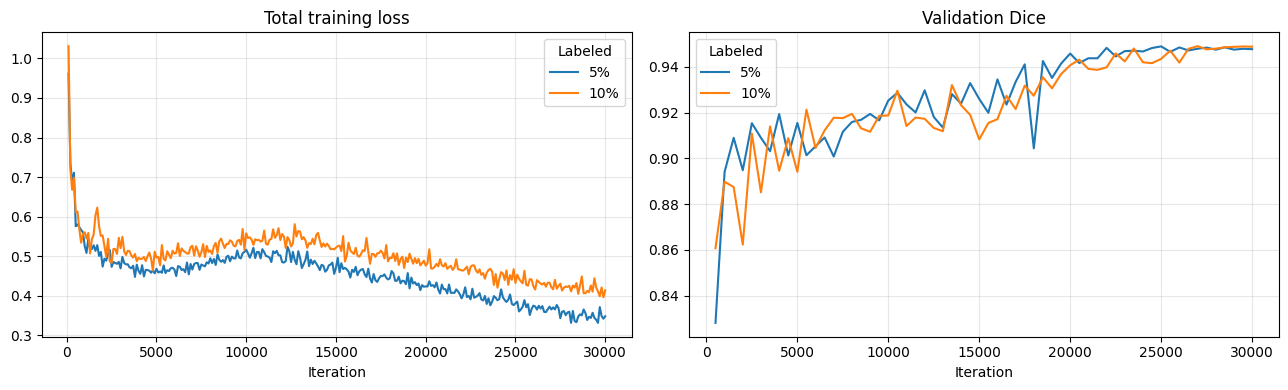

In [14]:
# ---- Results table (paper format: mean(std)) ----
df = pd.DataFrame(results)
table = pd.DataFrame({
    "Model": df["model"], "Labeled %": df["labeled_%"], "Seed": df["seed"],
    **{k.upper(): [f"{m:.2f}({s:.2f})" for m, s in zip(df[f"{k}_mean"], df[f"{k}_std"])]
       for k in ["dsc", "jaccard", "hd95", "asd"]}})
table.to_csv(RUN_ROOT / f"summary_{CFG.MODEL}.csv", index=False)
display(table)

# ---- Training curves ----
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ratio in CFG.LABELED_RATIOS:
    log = pd.read_csv(RUN_ROOT / f"{CFG.MODEL}_{ratio}p_s{CFG.SEEDS[0]}" / "log.csv")
    tr, va = log.dropna(subset=["loss"]), log.dropna(subset=["val_dice"])
    axes[0].plot(tr["iter"], tr["loss"].astype(float), label=f"{ratio}%")
    axes[1].plot(va["iter"], va["val_dice"].astype(float), label=f"{ratio}%")
axes[0].set(title="Total training loss", xlabel="Iteration"); axes[1].set(title="Validation Dice", xlabel="Iteration")
for ax in axes:
    ax.legend(title="Labeled"); ax.grid(alpha=.3)
plt.tight_layout(); plt.savefig(RUN_ROOT / f"curves_{CFG.MODEL}.png", dpi=150); plt.show()

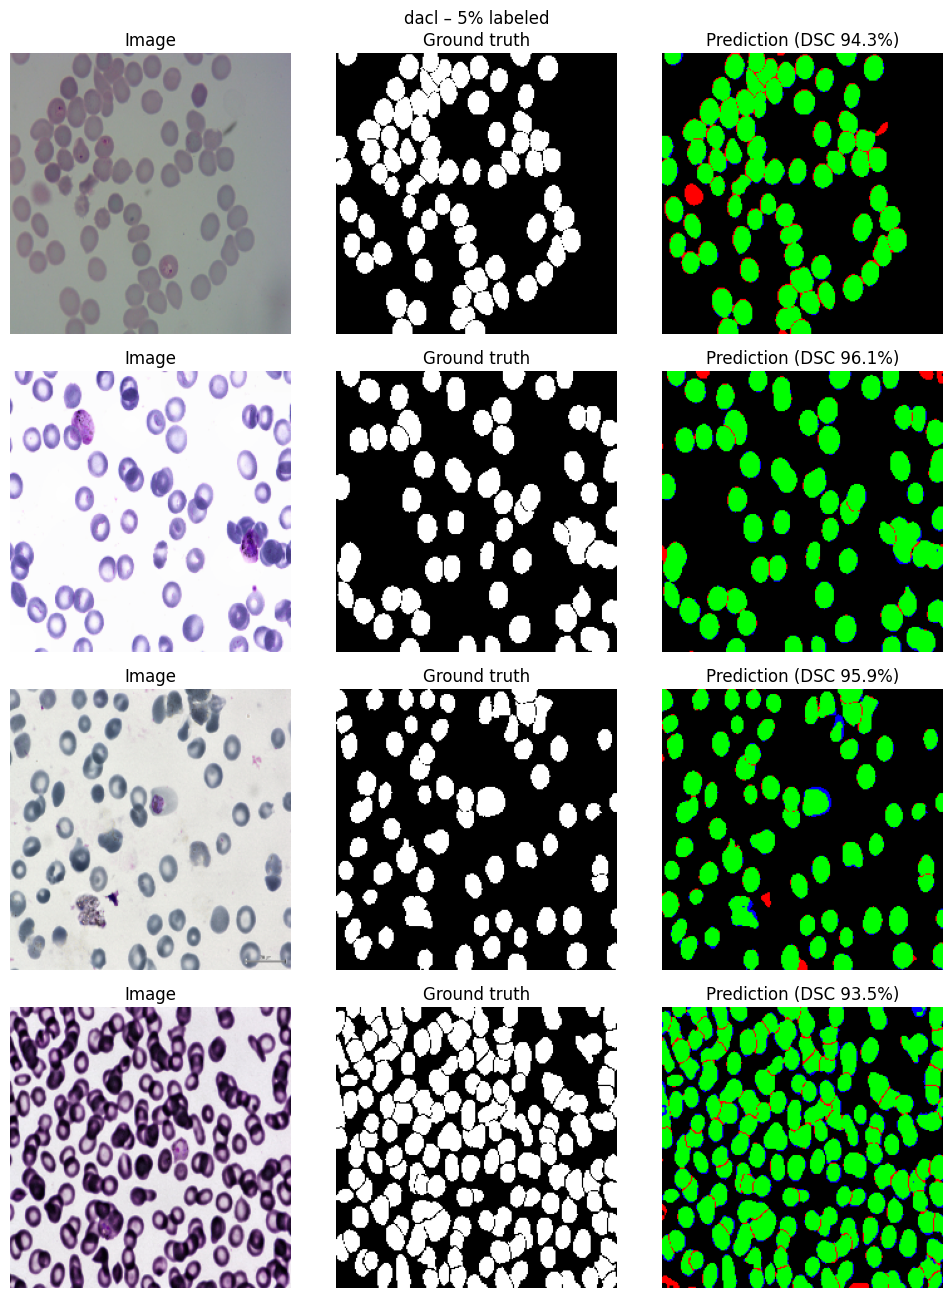

In [15]:
# ---- Test predictions: green = correct, red = false positive, blue = false negative ----
def show_predictions(ratio=None, n=4):
    ratio = ratio or CFG.LABELED_RATIOS[0]
    model = build_model(pretrained=False).to(DEVICE)
    ck = RUN_ROOT / f"{CFG.MODEL}_{ratio}p_s{CFG.SEEDS[0]}" / "best.pth"
    model.load_state_dict(torch.load(ck, map_location=DEVICE)["model"]); model.eval()
    ds = BloodCellDataset(SPLIT["test"][:n], build_eval_transform())
    fig, axes = plt.subplots(n, 3, figsize=(10, 3.3 * n))
    for i in range(n):
        b = ds[i]
        with torch.no_grad():
            p = model(b["image"][None].to(DEVICE)).argmax(1)[0].cpu().numpy().astype(bool)
        g = b["mask"].numpy().astype(bool)
        img = b["image"].permute(1, 2, 0).numpy() * np.array(AUG.STD) + np.array(AUG.MEAN)
        img = np.clip(img, 0, 1)
        err = np.zeros((*g.shape, 3)); err[p & g] = (0, 1, 0); err[p & ~g] = (1, 0, 0); err[~p & g] = (0, 0, 1)
        d = binary_metrics(p, g)["dsc"] * 100
        for ax, im, t in zip(axes[i], [img, g, err], ["Image", "Ground truth", f"Prediction (DSC {d:.1f}%)"]):
            ax.imshow(im, cmap="gray"); ax.set_title(t); ax.axis("off")
    plt.suptitle(f"{CFG.MODEL} – {ratio}% labeled"); plt.tight_layout(); plt.show()


show_predictions()

In [16]:
# ---- Package results (without last.pth) -> download from the Output tab ----
zip_path = Path(CFG.WORK_DIR) / f"results_{CFG.MODEL}"
tmp = Path(CFG.WORK_DIR) / "_pack"
shutil.rmtree(tmp, ignore_errors=True)
shutil.copytree(RUN_ROOT, tmp, ignore=shutil.ignore_patterns("last.pth"))
shutil.make_archive(str(zip_path), "zip", tmp)
shutil.rmtree(tmp)
print("Created", zip_path.with_suffix(".zip"))

Created /kaggle/working/results_dacl.zip
